# <font color = "gold"> Segmentation des clients d'un grossiste (Wholesale customers)

**Source :** UCI Machine Learning Repository - Wholesale customers
**Lien :** https://archive.ics.uci.edu/dataset/292/wholesale+customers

Le jeu de données décrit **440 clients d'un grossiste portugais** (Margarida Cardoso, 2014). Pour chaque
client, on connaît ses **dépenses annuelles** (en unités monétaires) dans six catégories de produits, ainsi
que son canal de vente et sa région.

**Objectif :** regrouper les clients qui ont des habitudes d'achat semblables (clustering), avec la même
démarche que pour `customer_segmentation` : préparation, ACP, Kmeans, CAH, comparaison puis déploiement.

### <font color = "gold"> Importer les librairies requises

In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import plotly.express as px

In [2]:
# Supprimer les warnings
import warnings
warnings.filterwarnings('ignore')

### <font color = "gold"> Importer et lire les données

In [3]:
# Importer les données
df = pd.read_csv('Wholesale customers data.csv')

#### Description des variables

| Variable | Type | Description |
|----------|------|-------------|
| `Channel` | Catégorielle | Canal de vente : 1 = Horeca (hôtels, restaurants, cafés), 2 = commerce de détail |
| `Region` | Catégorielle | Région : 1 = Lisbonne, 2 = Porto, 3 = autre région |
| `Fresh` | Numérique | Dépenses annuelles en produits frais |
| `Milk` | Numérique | Dépenses annuelles en produits laitiers |
| `Grocery` | Numérique | Dépenses annuelles en épicerie |
| `Frozen` | Numérique | Dépenses annuelles en surgelés |
| `Detergents_Paper` | Numérique | Dépenses annuelles en détergents et papier |
| `Delicassen` | Numérique | Dépenses annuelles en produits fins (épicerie fine) |

In [4]:
# Afficher les données
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [5]:
# Dimension des données
df.shape

(440, 8)

In [6]:
# Infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [7]:
# Décrire les données
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


### <font color = "gold"> Nettoyage des données

In [8]:
# Valeurs manquantes par colonne
df.isna().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

In [9]:
# Nombre de lignes en double
df.duplicated().sum()

np.int64(0)

**Il n'y a ni valeur manquante ni doublon.**

Les colonnes `Channel` et `Region` sont des **codes** (1, 2, 3) et non des quantités : une distance calculée
sur ces codes n'aurait pas de sens. On les **retire du clustering** et on les garde de côté pour
**interpréter** les classes à la fin.

In [10]:
# Garder Channel et Region pour l'interprétation
infos = df[['Channel', 'Region']]
# Garder uniquement les dépenses pour le clustering
df = df.drop(columns=['Channel', 'Region'])
df.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [11]:
# Distribution des dépenses
px.box(df, title='Dépenses annuelles par catégorie').show()

**Les dépenses sont très dispersées : quelques gros clients dépensent beaucoup plus que les autres.**
Comme pour `customer_segmentation`, on **normalise** chaque client (chaque ligne est ramenée à une norme
de 1). Le clustering compare alors la **répartition** des achats entre les catégories, et non leur montant
total : un petit restaurant et un grand restaurant auront le même profil.

In [12]:
# Renommer les index
df.index = ['Client' + str(i+1) for i in range(len(df))]
df.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Client1,12669,9656,7561,214,2674,1338
Client2,7057,9810,9568,1762,3293,1776
Client3,6353,8808,7684,2405,3516,7844
Client4,13265,1196,4221,6404,507,1788
Client5,22615,5410,7198,3915,1777,5185


In [13]:
# Données en format matriciel
x = df.values
x[:5]

array([[12669,  9656,  7561,   214,  2674,  1338],
       [ 7057,  9810,  9568,  1762,  3293,  1776],
       [ 6353,  8808,  7684,  2405,  3516,  7844],
       [13265,  1196,  4221,  6404,   507,  1788],
       [22615,  5410,  7198,  3915,  1777,  5185]])

In [14]:
# Importer normalize
from sklearn.preprocessing import normalize
# Normaliser x
x = normalize(x)
x[:5]

array([[0.70833271, 0.53987376, 0.42274083, 0.01196489, 0.14950522,
        0.07480852],
       [0.44219826, 0.61470384, 0.59953989, 0.11040858, 0.20634248,
        0.11128583],
       [0.39655169, 0.5497918 , 0.47963217, 0.15011913, 0.2194673 ,
        0.48961931],
       [0.85683654, 0.07725417, 0.27265036, 0.41365859, 0.03274905,
        0.11549369],
       [0.89541593, 0.21420297, 0.28499685, 0.1550101 , 0.07035835,
        0.20529434]])

### <font color = "gold"> Appliquer une ACP

In [15]:
# Importer PCA
from sklearn.decomposition import PCA
# Instantier le modèle PCA avec n_components = 2
pca_model = PCA(n_components = 2)
# Matrice des 2 composantes
feature_pca = pca_model.fit_transform(x)
# Convertir la matrice feature_pca en dataframe
New_df = pd.DataFrame(feature_pca, columns = ['PC1', 'PC2'])
New_df.head()

,PC1,PC2
0,-0.034037,-0.180421
1,-0.351057,-0.046644
2,-0.305375,0.055551
3,0.383677,0.161789
4,0.318591,-0.076970


In [16]:
# Part de variance des 2 composantes
np.round(sum(pca_model.explained_variance_ratio_)*100, 2)

np.float64(82.8)

**Les deux premières composantes résument environ 83 % de l'information : on peut visualiser les classes dans ce plan.**

### <font color = "gold"> Kmeans

In [17]:
# Importer KMeans
from sklearn.cluster import KMeans

##### <font color = "bisque"> La méthode elbow (coude)

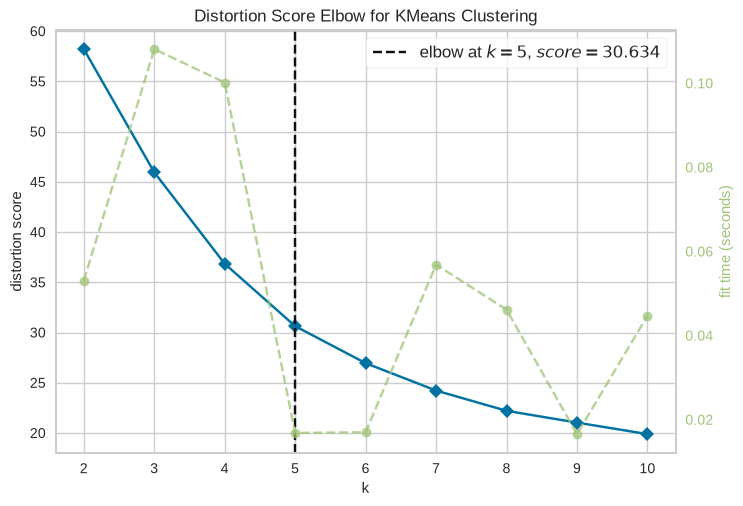

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [18]:
# importer KElbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'random', max_iter=500, n_init=10, random_state=42)
# Instantier KElbowVisualizer
# force_model=True : yellowbrick 1.5 ne reconnaît plus KMeans comme modèle de clustering avec scikit-learn >= 1.6
Elbow_M = KElbowVisualizer(kmeans_model, k=10, force_model=True)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

**La plus forte cassure de la courbe se situe à k = 2 : on retient 2 classes.**

#### <font color = "bisque"> Appliquer Kmeans en utilisant le k optimal

In [19]:
# Instantier le modèle
kmeans_model = KMeans(n_clusters = 2, init = 'random', max_iter=500, n_init=10, random_state=42)
# Entrainer le modèle
kmeans_model.fit(x)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",500
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 6)","[[0.87,0

#### <font color = "bisque"> Prédiction

In [20]:
# Prédiction de la partition des données
kmeans_partition = kmeans_model.predict(x)
# Afficher la partition
kmeans_partition[:100]

array([0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1,
       1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0], dtype=int32)

In [21]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts()
val

0    250
1    190
Name: count, dtype: int64

In [22]:
# Fonction de visualisation du diagramme en barre des nombres d'observations
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

In [23]:
# Visualiser le diagramme des nombres d'observations
bar_plot(val)

In [24]:
# Fonction de visualisation des classes
def scatter_plot(New_df, Pred):
  fig = px.scatter(New_df, x='PC1', y='PC2', color=Pred.astype(str))
  fig.show()

In [25]:
# Visualiser les classes
scatter_plot(New_df, kmeans_partition)

##### <font color = "bisque"> Indice de silhouette de la partition du Kmeans

In [26]:
# Silhouette score
from sklearn.metrics import silhouette_score
sil_km = silhouette_score(x, kmeans_partition)
print(f"Silhouette score : {sil_km}")

Silhouette score : 0.5002248259665941


### <font color = "gold"> CAH

In [27]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

**Choix du critère de liaison.** Avec le lien moyen (`average`) utilisé pour `customer_segmentation`, la CAH
isole ici un seul client atypique dans sa propre classe et met les 439 autres ensemble : la partition n'est
pas exploitable. On utilise donc le **critère de Ward**, qui fusionne à chaque étape les deux classes dont
la réunion augmente le moins la variance intra-classe : il donne des classes plus équilibrées.

In [28]:
# Comparaison rapide : lien moyen
from sklearn.cluster import AgglomerativeClustering
test_average = AgglomerativeClustering(n_clusters=2, linkage='average').fit_predict(x)
pd.Series(test_average).value_counts()

0    439
1      1
Name: count, dtype: int64

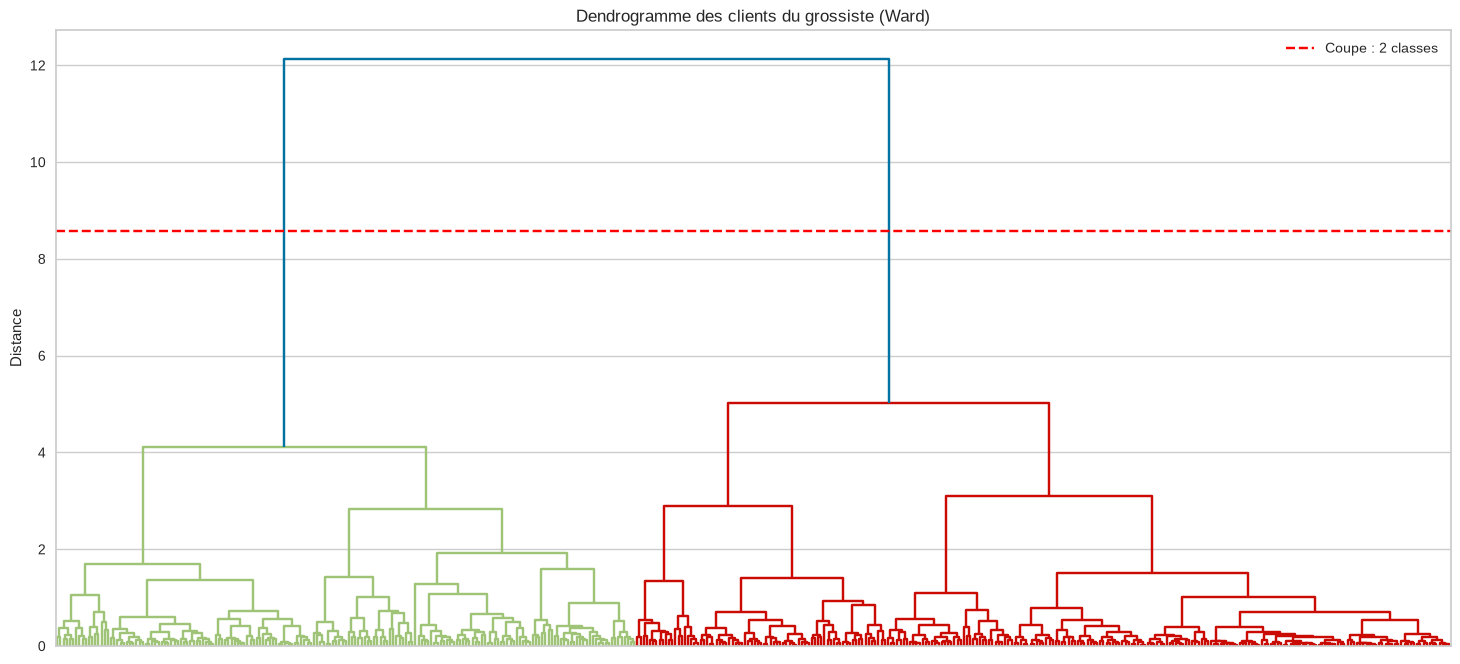

In [29]:
# Visualiser le dendrogramme (Ward)
Z = linkage(x, 'ward') # matrice des liaisons
# Hauteur de coupe : entre la fusion qui donne 2 classes et la dernière fusion
seuil = (Z[-2, 2] + Z[-1, 2]) / 2
plt.figure(figsize=(18, 8))
dendro = dendrogram(Z, no_labels=True, color_threshold=seuil)
plt.axhline(y=seuil, color='red', linestyle='--', label='Coupe : 2 classes')
plt.title('Dendrogramme des clients du grossiste (Ward)')
plt.ylabel('Distance')
plt.legend()
plt.show()

**La dernière fusion est de loin la plus haute : en coupant au niveau de la ligne rouge, on obtient 2 classes, comme avec le Kmeans.**

In [30]:
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters=2, linkage='ward')
# Entrainer le modèle
cah_model.fit(x)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",2
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" and ""l2"" are accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and metric is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'ward'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False
Name,Type,Value
"children_ children_: array-like of shape (n_samples-1, 2)The children of each non-leaf node. Values less than `n_samples`correspond to leaves of the tree which are the original samples.A node `i` greater than or equal to `n_samples

In [31]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(x)
# Afficher la partition
cah_partition[:100]

array([1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1,
       1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0])

In [32]:
# Nombre d'observations dans chaque classe
val1 = pd.Series(cah_partition).value_counts()
val1

0    257
1    183
Name: count, dtype: int64

In [33]:
# Diagramme en barre des nombres d'observations
bar_plot(val1)

In [34]:
# Visualiser les classes
scatter_plot(New_df, cah_partition)

In [35]:
# Silhouette score
sil_cah = silhouette_score(x, cah_partition)
print(f"Silhouette score : {sil_cah}")

Silhouette score : 0.49090497987749027


### <font color = "gold"> Comparer Kmeans et CAH

In [36]:
# Diagramme en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_km, sil_cah]
fig = px.bar(x = Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [37]:
# Les deux méthodes donnent-elles les mêmes classes ?
pd.crosstab(kmeans_partition, cah_partition, rownames=['Kmeans'], colnames=['CAH'])

CAH,0,1
Kmeans,,
0,245,5
1,12,178


**Les deux méthodes trouvent presque les mêmes groupes, mais le Kmeans obtient un indice de silhouette un peu
plus élevé. On retient donc le Kmeans comme meilleur modèle.** Il a aussi l'avantage de posséder une
méthode `predict` pour classer un nouveau client.

### <font color = "gold"> Interpréter les classes

In [38]:
# Profil moyen de chaque classe (en unités monétaires)
profil = df.groupby(kmeans_partition).mean().round(0)
profil

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,17447.0,3120.0,3930.0,3925.0,839.0,1302.0
1,4834.0,9318.0,13242.0,1949.0,5568.0,1818.0


In [39]:
# Part de chaque catégorie dans les achats (données normalisées)
profil_norm = pd.DataFrame(x, columns=df.columns, index=df.index).groupby(kmeans_partition).mean().round(2)
profil_norm

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.87,0.17,0.23,0.22,0.05,0.07
1,0.26,0.48,0.66,0.13,0.25,0.11


In [40]:
# Comparer les classes au canal de vente (1 = Horeca, 2 = commerce de détail)
pd.crosstab(kmeans_partition, infos['Channel'].values, rownames=['Classe'], colnames=['Channel'])

Channel,1,2
Classe,,
0,218,32
1,80,110


**Interprétation :**
- une classe achète surtout des **produits frais** (et des surgelés) : ce sont majoritairement des
  **hôtels, restaurants et cafés** (canal Horeca) ;
- l'autre classe achète surtout de l'**épicerie, du lait et des détergents** : on y trouve la majorité des
  **commerces de détail**.

Le clustering retrouve donc, sans l'avoir utilisé, le type de client.

In [41]:
# Noms des classes : la classe où la part des produits frais est la plus forte est le profil Horeca
classe_frais = profil_norm['Fresh'].idxmax()
noms_classes = {}
for c in profil_norm.index:
    if c == classe_frais:
        noms_classes[c] = 'client « produits frais » (profil hôtel / restaurant / café)'
    else:
        noms_classes[c] = 'client « épicerie, lait et détergents » (profil commerce de détail)'
noms_classes

{0: 'client « produits frais » (profil hôtel / restaurant / café)',
 1: 'client « épicerie, lait et détergents » (profil commerce de détail)'}

In [42]:
# Les clients de chaque classe
cluster_names = []
for i in range(2):
  cluster_names.append(list(df.index[kmeans_partition == i]))
# Les clients de la classe 0
print(cluster_names[0][:50])

['Client1', 'Client4', 'Client5', 'Client6', 'Client7', 'Client12', 'Client13', 'Client14', 'Client15', 'Client16', 'Client19', 'Client21', 'Client22', 'Client23', 'Client25', 'Client26', 'Client27', 'Client28', 'Client30', 'Client31', 'Client33', 'Client34', 'Client37', 'Client40', 'Client41', 'Client42', 'Client51', 'Client53', 'Client55', 'Client59', 'Client65', 'Client68', 'Client70', 'Client71', 'Client73', 'Client74', 'Client76', 'Client79', 'Client81', 'Client84', 'Client85', 'Client88', 'Client89', 'Client90', 'Client91', 'Client92', 'Client94', 'Client100', 'Client104', 'Client105']


### <font color = "gold"> Déploiement du meilleur modèle (Kmeans)

Le modèle est déployé dans l'**application Streamlit** commune aux deux nouveaux jeux de données
(`app.py`, page « Clients d'un grossiste »). L'application reproduit exactement les étapes ci-dessous :
elle normalise les dépenses saisies, puis prédit la classe avec le Kmeans.

In [43]:
# Fonction de prédiction utilisée par l'application
def predire_classe(nouveau_client):
    client = normalize(np.array(nouveau_client, dtype=float).reshape(1, -1))
    return kmeans_model.predict(client)[0]

def affecter_client(*valeurs):
    classe = predire_classe(valeurs)
    return "C'est un " + noms_classes[classe]

In [44]:
# Test sur deux clients du jeu de données (un de chaque classe)
for i in [0, 9]:
    print(df.index[i], ':', affecter_client(*df.iloc[i].values), '| classe Kmeans :', kmeans_partition[i])

Client1 : C'est un client « produits frais » (profil hôtel / restaurant / café) | classe Kmeans : 0
Client10 : C'est un client « épicerie, lait et détergents » (profil commerce de détail) | classe Kmeans : 1


In [45]:
# Sauvegarder le modèle (facultatif : l'application le réentraîne à partir du CSV)
import joblib
joblib.dump(kmeans_model, 'kmeans_wholesale.joblib')

['kmeans_wholesale.joblib']